# AgentAccess

**Authors:** Alexander Michels

This notebook walks through the a generalized Agent-Based Model for spatial accessibility analysis.

In [1]:
import access
import geopandas as gpd
from IPython.display import Image
import math
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from tqdm import tqdm
import sys
sys.path.append("../")
from agentaccess.Model import AgentAccess
# pandas gives warnings too often
pd.options.mode.chained_assignment = None

In [2]:
figsize=(10,10)

## Data

The AgentAccess model has the exact same data requirements as traditional place-based spatial accessibility methods:

* demand: a population of people needing a good/service
* supply: a good/service distributed across space
* spatial impedance: the "cost" to overcome the distances between supply and demand

We will first load our population dataset, the general population within Cook County, IL.

In [3]:
pop = gpd.read_file("../data/svi/SVI2018_US_tract.shp")
pop = pop[pop["STCNTY"] == "17031"]
pop = pop.to_crs("EPSG:4326")
print(len(pop))
pop.head()

1318


,ST,STATE,ST_ABBR,STCNTY,COUNTY,FIPS,LOCATION,AREA_SQMI,E_TOTPOP,M_TOTPOP,...,F_THEME4,F_TOTAL,E_UNINSUR,M_UNINSUR,EP_UNINSUR,MP_UNINSUR,E_DAYPOP,Shape_STAr,Shape_STLe,geometry
184,17,ILLINOIS,IL,17031,Cook,17031381700,"Census Tract 3817, Cook County, Illinois",0.075986,0,11,...,-999,-999,0,11,-999.0,-999.0,551,0.000021,0.020359,"POLYGON ((-87.62892 41.80919, -87.62608 41.809..."
185,17,ILLINOIS,IL,17031,Cook,17031980000,"Census Tract 9800, Cook County, Illinois",7.679554,0,11,...,-999,-999,0,11,-999.0,-999.0,38202,0.002171,0.222431,"POLYGON ((-87.94025 42.00717, -87.93895 42.006..."
186,17,ILLINOIS,IL,17031,Cook,17031980100,"Census Tract 9801, Cook County, Illinois",1.151272,0,11,...,-999,-999,0,11,-999.0,-999.0,6449,0.000323,0.076961,"POLYGON ((-87.7623 41.79274, -87.75251 41.7928..."
12180,17,ILLINOIS,IL,17031,Cook,17031020100,"Census Tract 201, Cook County, Illinois",0.158747,3836,361,...,0,0,569,245,14.8,6.3,3714,0.000044,0.027301,"POLYGON ((-87.6902 42.01682, -87.6902 42.01744..."
12181,17,ILLINOIS,IL,17031,Cook,17031020200,"Census Tract 202, Cook County, Illinois",0.479524,6739,510,...,0,1,628,396,9.3,6.0,3249,0.000135,0.051852,"POLYGON ((-87.70875 42.0155, -87.70866 42.0191..."


The dataset we are using has an estimate of the percentage of households without vehicles (`EPNOVEH`) and we will use this data to simulate agents with and without vehicles in our model:

In [4]:
pop["no_vehicle"] = (pop["E_TOTPOP"] * pop["EP_NOVEH"] / 100.0).astype(int)
pop["vehicle"] = pop["E_TOTPOP"] - pop["no_vehicle"]
print(sum(pop["E_TOTPOP"]))
pop.head()

5223719


,ST,STATE,ST_ABBR,STCNTY,COUNTY,FIPS,LOCATION,AREA_SQMI,E_TOTPOP,M_TOTPOP,...,E_UNINSUR,M_UNINSUR,EP_UNINSUR,MP_UNINSUR,E_DAYPOP,Shape_STAr,Shape_STLe,geometry,no_vehicle,vehicle
184,17,ILLINOIS,IL,17031,Cook,17031381700,"Census Tract 3817, Cook County, Illinois",0.075986,0,11,...,0,11,-999.0,-999.0,551,0.000021,0.020359,"POLYGON ((-87.62892 41.80919, -87.62608 41.809...",0,0
185,17,ILLINOIS,IL,17031,Cook,17031980000,"Census Tract 9800, Cook County, Illinois",7.679554,0,11,...,0,11,-999.0,-999.0,38202,0.002171,0.222431,"POLYGON ((-87.94025 42.00717, -87.93895 42.006...",0,0
186,17,ILLINOIS,IL,17031,Cook,17031980100,"Census Tract 9801, Cook County, Illinois",1.151272,0,11,...,0,11,-999.0,-999.0,6449,0.000323,0.076961,"POLYGON ((-87.7623 41.79274, -87.75251 41.7928...",0,0
12180,17,ILLINOIS,IL,17031,Cook,17031020100,"Census Tract 201, Cook County, Illinois",0.158747,3836,361,...,569,245,14.8,6.3,3714,0.000044,0.027301,"POLYGON ((-87.6902 42.01682, -87.6902 42.01744...",617,3219
12181,17,ILLINOIS,IL,17031,Cook,17031020200,"Census Tract 202, Cook County, Illinois",0.479524,6739,510,...,628,396,9.3,6.0,3249,0.000135,0.051852,"POLYGON ((-87.70875 42.0155, -87.70866 42.0191...",289,6450


Next we will run a quick sanity check to ensure that we have no negative populations and we have the same number of total population as before:

In [5]:
for i, row in pop.iterrows():
    assert row["vehicle"] >= 0
    assert row["no_vehicle"] >= 0
    assert row["vehicle"] + row["no_vehicle"] == row["E_TOTPOP"]

In [6]:
# load the dentists
hos = access.Datasets.load_data("chi_doc")
hos["geoid"] = hos["geoid"].astype(str)
hos = pop[["FIPS", "geometry"]].merge(hos[["geoid", "dentist"]], left_on="FIPS", right_on="geoid")
hos = hos.to_crs("EPSG:4326")
print(len(hos))
hos.head()

1318


,FIPS,geometry,geoid,dentist
0,17031381700,"POLYGON ((-87.62892 41.80919, -87.62608 41.809...",17031381700,1
1,17031980000,"POLYGON ((-87.94025 42.00717, -87.93895 42.006...",17031980000,2
2,17031980100,"POLYGON ((-87.7623 41.79274, -87.75251 41.7928...",17031980100,0
3,17031020100,"POLYGON ((-87.6902 42.01682, -87.6902 42.01744...",17031020100,3
4,17031020200,"POLYGON ((-87.70875 42.0155, -87.70866 42.0191...",17031020200,1


<Axes: >

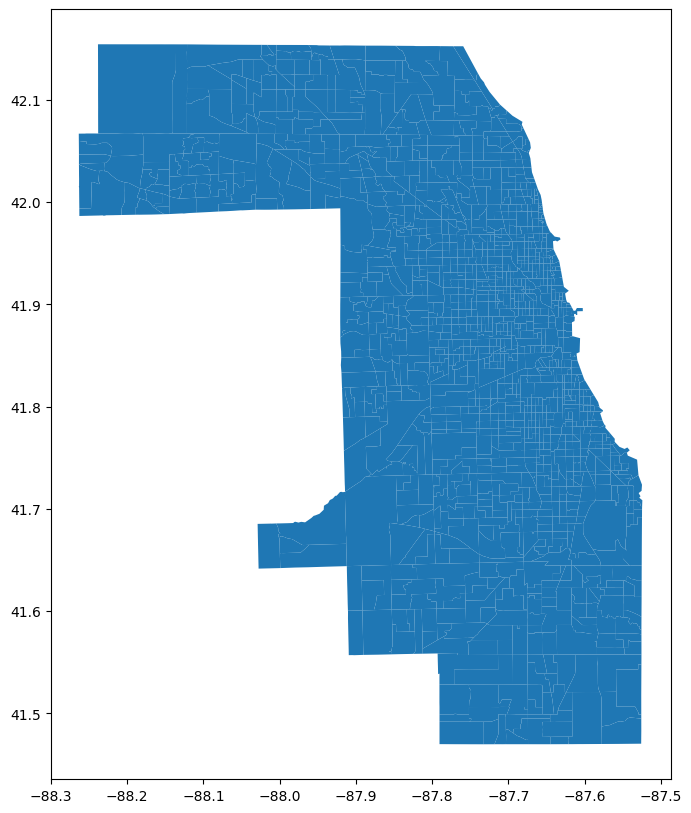

In [7]:
hos.plot(figsize=figsize)

In [8]:
# get car travel times
car = pd.read_csv("../data/travel_times/17031-output-TRACT-CAR.csv")
car["origin"] = car["origin"].astype(str)
car["destination"] = car["destination"].astype(str)
car = car.rename(columns={"minutes": "car"})
print(len(car))
car.head()

3780024


,origin,destination,car
0,17031010100,17007010100,101.35
1,17031010100,17007010200,96.10
2,17031010100,17007010300,96.43
3,17031010100,17007010400,96.17
4,17031010100,17007010500,107.13


In [9]:
# get the transit/walking times
transit = pd.read_csv("../data/travel_times/17031-output-TRACT-TRANSIT,WALK.csv")
transit["origin"] = transit["origin"].astype(str)
transit["destination"] = transit["destination"].astype(str)
transit = transit.rename(columns={"minutes": "transit"})
print(len(transit))
transit.head()

2853575


,origin,destination,transit
0,17031010100,17007010100,541.58
1,17031010100,17007010200,542.43
2,17031010100,17007010300,561.87
3,17031010100,17007010400,567.78
4,17031010100,17007010500,534.08


In [10]:
# get the walking times
walk = pd.read_csv("../data/travel_times/17031-output-TRACT-WALK.csv")
walk["origin"] = walk["origin"].astype(str)
walk["destination"] = walk["destination"].astype(str)
walk = walk.rename(columns={"minutes": "walk"})
print(len(walk))
walk.head()

234772


,origin,destination,walk
0,17031010100,17031010100,0.17
1,17031010100,17031010201,19.35
2,17031010100,17031010202,10.35
3,17031010100,17031010300,10.83
4,17031010100,17031010400,29.22


In [11]:
travel_times = pd.merge(car, transit, how="outer",
                       left_on=["origin", "destination"],
                       right_on=["origin", "destination"])
print(len(travel_times))
travel_times.head()

3782602


,origin,destination,car,transit
0,17031010100,17007010100,101.35,541.58
1,17031010100,17007010200,96.10,542.43
2,17031010100,17007010300,96.43,561.87
3,17031010100,17007010400,96.17,567.78
4,17031010100,17007010500,107.13,534.08


In [12]:
travel_times = pd.merge(travel_times, walk, how="outer",
                       left_on=["origin", "destination"],
                       right_on=["origin", "destination"])
print(len(travel_times))
travel_times.head()

3782602


,origin,destination,car,transit,walk
0,17031010100,17007010100,101.35,541.58,NaN
1,17031010100,17007010200,96.10,542.43,NaN
2,17031010100,17007010300,96.43,561.87,NaN
3,17031010100,17007010400,96.17,567.78,NaN
4,17031010100,17007010500,107.13,534.08,NaN


## Model

The model executes across a number of time steps set by the user.

In [13]:
time_steps = 10

In [14]:
# intialize our model
model = AgentAccess(
    pop,
    "FIPS",
    "E_TOTPOP",
    hos,
    "GEOID",
    "dentist",
    travel_times,
    "origin",
    "destination",
    ["car", "transit"],
    time_steps,
    cost_prop_fields=["vehicle", "no_vehicle"],
    pop_per_agent=1000,
    output_path="../outputs/",
    processes=3,
)

In [ ]:
model.run_model()

Running Model:   0%|                                     | 0/10 [00:00<?, ?it/s]

In [ ]:
model.save_gif()

Let's view the gif from the model!

In [ ]:
Image(filename=os.path.join(model.output_dir, "movie.gif"))

We can also inspect all of the internal data that our model generated:

In [ ]:
model.cost_df.head()

In [ ]:
model.demand_df.head()

In [ ]:
model.supply_df.head()

In [ ]:
model.spatial_units_df.head()

In [ ]:
def normalize_columns(df, columns, to_flip=[]):
    for column in columns:
        df[column] = (df[column] - df[column].min()) / (df[column].max() - df[column].min())
        if column in to_flip:
            df[column] = 1 - df[column]
    return df

def average_columns(df, new_column, columns_to_average):
    df[new_column] = df[columns_to_average].mean(axis=1)
    return df

ABMs have some randomness, so to account for this, we will take averages over the last half of the time steps:

In [ ]:
last_portion = 2
df = average_columns(model.spatial_units_df, "D/S Ratio", [f"D/S Ratio {x}" for x  in range(time_steps - (time_steps//last_portion), time_steps)])
df = average_columns(df, "Time", [f"Time {x}" for x  in range(time_steps - (time_steps//last_portion), time_steps)])
df = average_columns(df, "Cost", [f"Cost {x}" for x  in range(time_steps - (time_steps//last_portion), time_steps)])
df = df[["D/S Ratio", "Time", "Cost", "geometry"]]
df.head()

In [ ]:
cols = ["D/S Ratio", "Time", "Cost"]
model_result = df
# model_result = normalize_columns(df, columns=cols)
model_result.head()

In [ ]:
model_result.plot(column="D/S Ratio", figsize=figsize, legend=True)

In [ ]:
model_result.plot(column="Time", figsize=figsize, legend=True)

In [ ]:
model_result.plot(column="Cost", figsize=figsize, legend=True)